## **PROJET NLP – CLASSIFICATION & ANALYSE DE SENTIMENT DES DONNÉES TWITTER**



## 1. Contexte

Les réseaux sociaux, notamment Twitter (X), génèrent chaque jour des millions de messages exprimant :

- des opinions,
- des émotions,
- des avis sur des produits,
- des réactions à des événements,
- des sentiments envers des marques ou services.

Ces données textuelles sont très riches, mais elles sont :

- non structurées,
- bruyantes,
- difficiles à analyser manuellement à grande échelle.

Le traitement automatique du langage naturel (NLP) permet d’exploiter ces textes afin d’extraire automatiquement des informations utiles, notamment le sentiment exprimé dans les tweets.

Dans ce projet, nous utilisons des techniques de NLP et de Machine Learning pour analyser et classifier automatiquement des tweets selon leur polarité émotionnelle (positive ou négative).

---

# 2. Objectif du projet

L’objectif principal de ce projet est de développer un système capable de :

- nettoyer et préparer des données textuelles issues de Twitter,
- transformer les textes en représentations numériques exploitables par une machine,
- entraîner un modèle de Machine Learning,
- classifier automatiquement les tweets selon leur sentiment :

  - positif,
  - négatif.

Le projet vise également à comprendre comment une machine peut prendre des décisions à partir du texte grâce aux probabilités et aux modèles statistiques.

---

# 3. Problématique

Comment permettre à une machine d’identifier automatiquement le sentiment exprimé dans un tweet, alors que le langage humain est ambigu, contextuel et non structuré ?

Plus précisément :

- Comment transformer un texte brut en données exploitables ?
- Comment extraire les mots importants d’un tweet ?
- Comment entraîner un modèle capable de reconnaître des sentiments à partir d’exemples annotés ?
- Comment améliorer la précision des prédictions malgré :

  - l’ironie,
  - les fautes,
  - les emojis,
  - les abréviations,
  - le langage informel utilisé sur Twitter ?

---

# 4. Compétences acquises

À travers ce projet, plusieurs compétences techniques et analytiques sont développées.

## Compétences en NLP

- Compréhension des concepts fondamentaux du NLP
- Nettoyage et prétraitement de données textuelles
- Tokenisation
- Gestion des stop words
- Analyse de sentiment
- Classification de texte

---

## Compétences en Machine Learning

- Compréhension de l’apprentissage supervisé
- Préparation des données pour l’entraînement
- Séparation train/test
- Entraînement d’un modèle de classification
- Évaluation des performances du modèle

---

## Compétences techniques en Python

- Manipulation de données avec Python
- Utilisation de bibliothèques NLP :

  - NLTK
  - scikit-learn
  - Pandas

- Traitement de fichiers CSV
- Visualisation et exploration des données

---

## Compétences analytiques

- Compréhension du comportement des données textuelles
- Interprétation des résultats d’un modèle NLP
- Analyse des erreurs de classification
- Compréhension des limites du NLP et du Machine Learning

# **Workflow & Architecture du Projet NLP**

## **Vue d'ensemble**

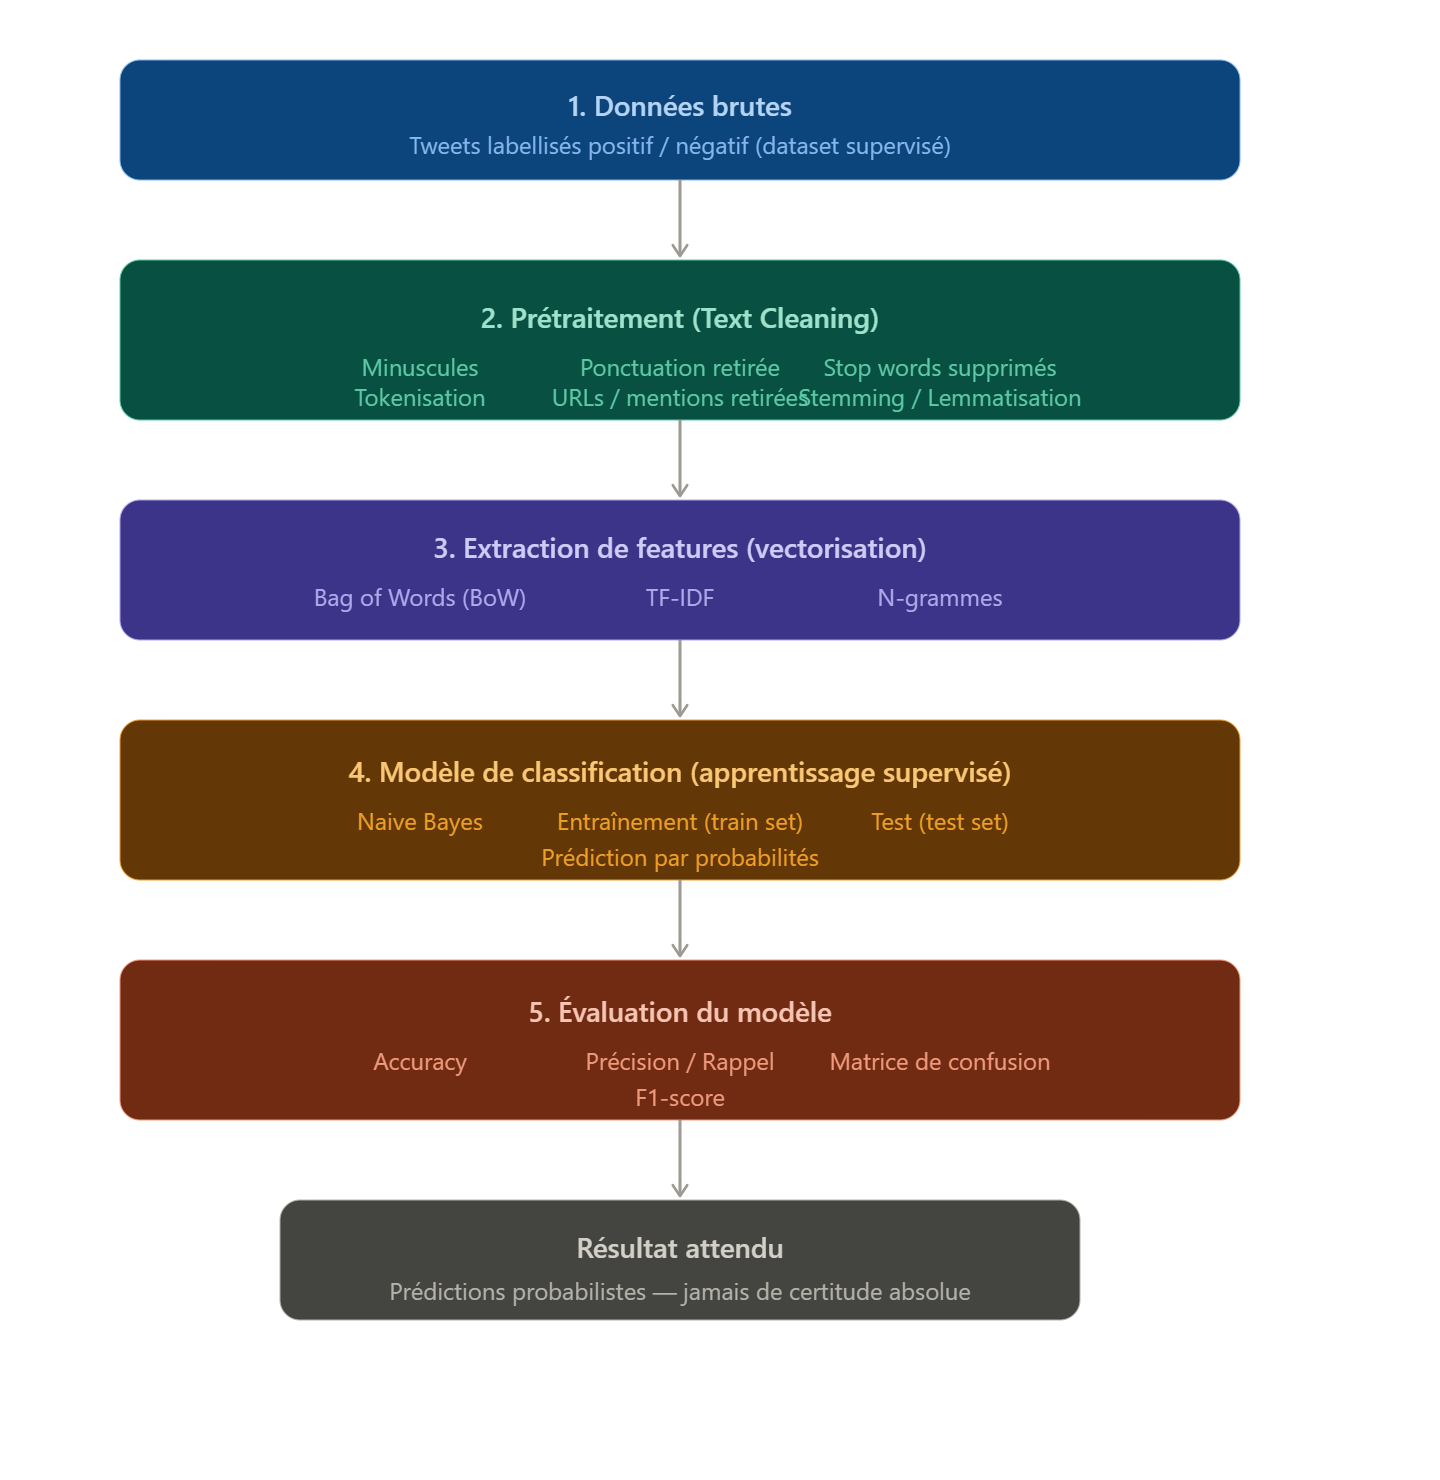

# **Architecture Technique**

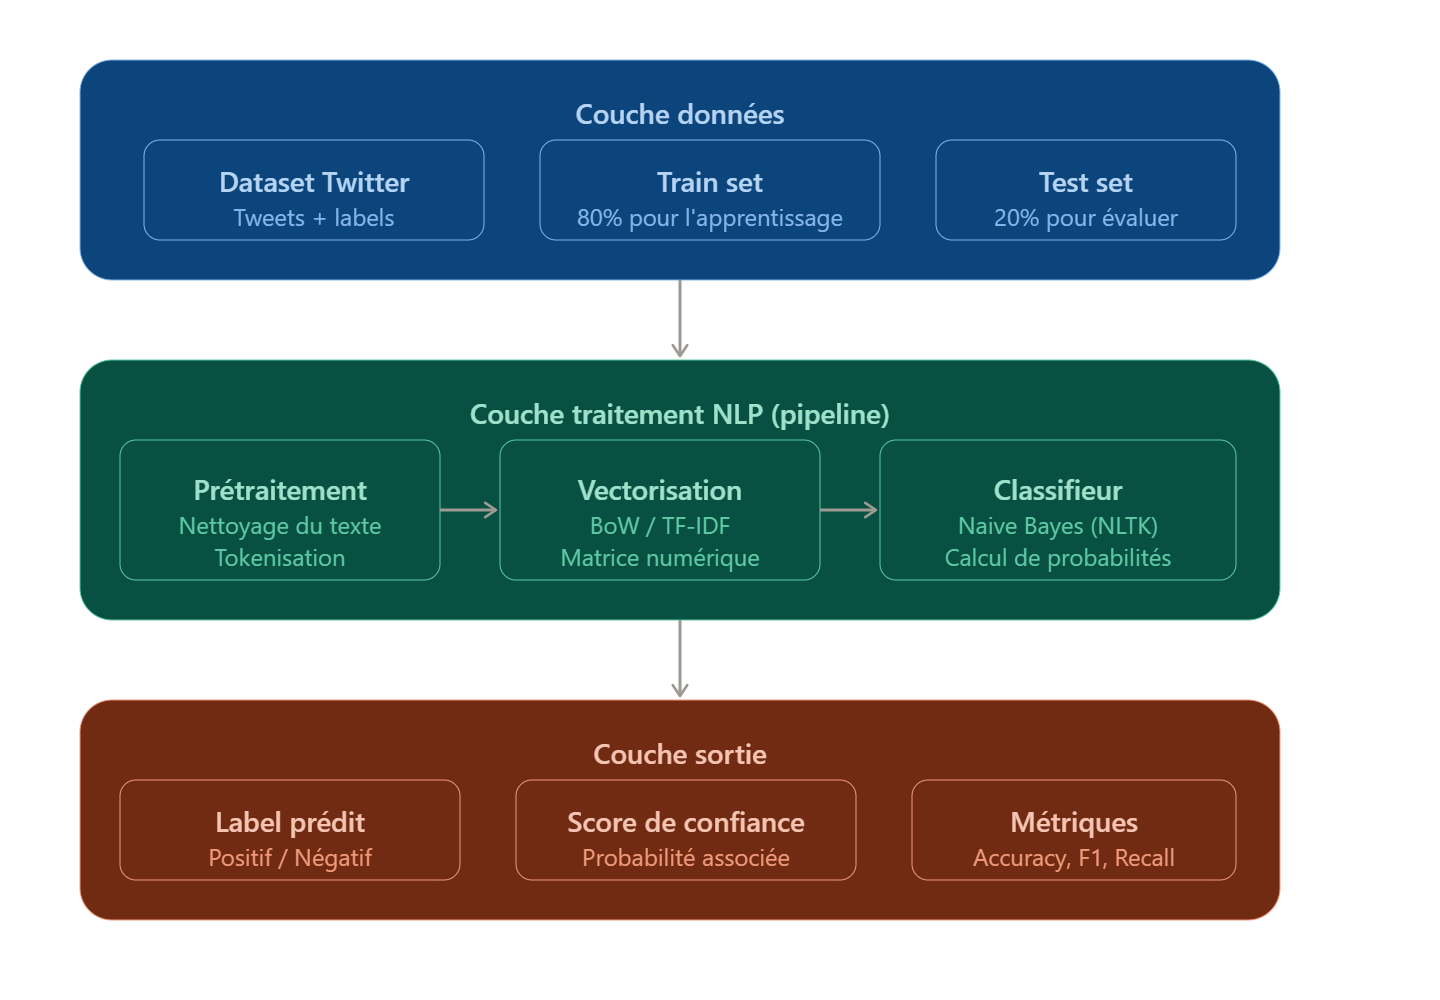

In [1]:
#Importation des modules
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
import pandas as pd 
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Importation de la base de données
columns = ['targets', 'ids', 'date', 'flag', 'user', 'text']
df = pd.read_csv('Twetter.csv', encoding='ISO-8859-1', names=columns)
df

,targets,ids,date,flag,user,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all...."
...,...,...,...,...,...,...
1599995,4,2193601966,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,AmandaMarie1028,Just woke up. Having no school is the best fee...
1599996,4,2193601969,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,TheWDBoards,TheWDB.com - Very cool to hear old Walt interv...
1599997,4,2193601991,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,bpbabe,Are you ready for your MoJo Makeover? Ask me f...
1599998,4,2193602064,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,tinydiamondz,Happy 38th Birthday to my boo of alll time!!! ...


# **Description des données**

| Colonne | Description |
|---|---|
| **target** | Représente la polarité du sentiment exprimé dans le texte. <br><br> - **0** : sentiment négatif <br> - **4** : sentiment positif |
| **ids** | Identifiant unique associé à chaque enregistrement. |
| **date** | Date et heure de publication du tweet ou du message. |
| **flag** | Marqueur indiquant la provenance des données. <br><br> - **NO_QUERY** : les données ne proviennent pas d’une requête spécifique <br> - Autres valeurs : peuvent indiquer la requête ou l’origine des données |
| **user** | Nom d’utilisateur de l’auteur du tweet ou du message. |
| **text** | Contenu textuel du tweet exprimant un sentiment ou une opinion. |

In [3]:
# Informaton sur la base de données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 6 columns):
 #   Column   Non-Null Count    Dtype
---  ------   --------------    -----
 0   targets  1600000 non-null  int64
 1   ids      1600000 non-null  int64
 2   date     1600000 non-null  str  
 3   flag     1600000 non-null  str  
 4   user     1600000 non-null  str  
 5   text     1600000 non-null  str  
dtypes: int64(2), str(4)
memory usage: 73.2 MB


In [4]:
df.isnull().sum()

targets    0
ids        0
date       0
flag       0
user       0
text       0
dtype: int64

In [5]:
df = df[['targets', 'text']]
df.sample(5)

,targets,text
563788,0,Waiting for the iPhone 3.0 software update. 10...
1234879,4,Uh...it is nice in here!
1518679,4,@WinGreenHill no problem
598160,0,@keigee omg you're sick too?! is that why you...
1453349,4,@pandalion Haha! Heeey don't sell yourself sho...


In [6]:
df['targets'].value_counts()

targets
0    800000
4    800000
Name: count, dtype: int64

In [7]:
df.targets.unique()

array([0, 4])

In [8]:
#Remplacer le 4 par 1
df.loc[df['targets'] == 4, 'targets'] = 1
df.targets.unique()

array([0, 1])

## **Distribution des sentiments(Positif/Négatif)**

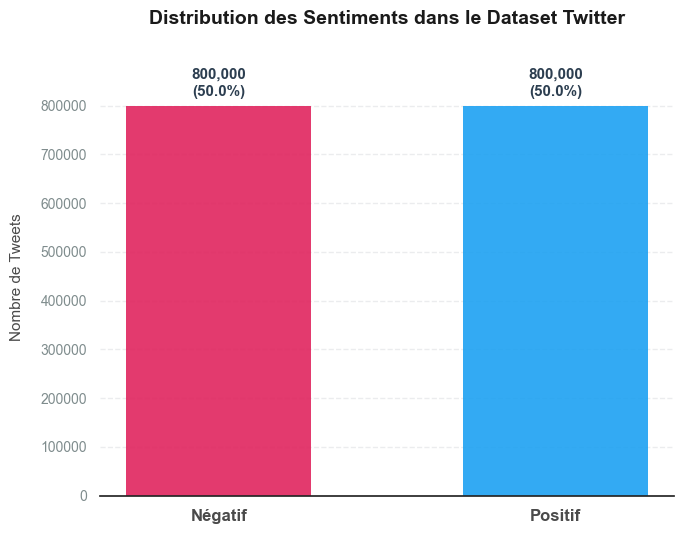

In [11]:

# 1. Configuration du style moderne
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(7, 5.5))

# Calcul des comptes et proportions
# Note : Sur Twitter Sentiment140, les étiquettes sont souvent 0 (Négatif) et 4 (Positif)
target_counts = df['targets'].value_counts()
target_proportions = df['targets'].value_counts(normalize=True)

# 2. Palette de couleurs "Social Media / Modern"
# Un bleu Twitter moderne pour le positif et un rouge/rose doux pour le négatif
colors = ['#1DA1F2', '#E0245E'] if target_counts.index[0] == 1 else ['#E0245E', '#1DA1F2']

# 3. Création du graphique à barres
bars = ax.bar(
    target_counts.index.astype(str), # Converti en str pour éviter les décalages d'axes si les valeurs sont 0 et 4
    target_counts.values, 
    color=colors, 
    width=0.55, 
    edgecolor='none',
    alpha=0.9
)

# 4. Ajout des étiquettes au-dessus des barres (Propre et aligné)
# Utilisation de max() pour calculer un espacement (padding) dynamique et précis
max_value = max(target_counts.values)
v_padding = max_value * 0.018 

for bar, count, prop in zip(bars, target_counts, target_proportions):
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2, 
        yval + v_padding,
        f"{count:,}\n({prop:.1%})", # Séparateur de milliers pour la clarté des gros volumes Twitter
        ha='center', 
        va='bottom', 
        fontsize=11, 
        fontweight='bold',
        color='#2C3E50',
        linespacing=1.3 # Donne de l'espace entre le nombre et le pourcentage
    )

# 5. Titres et labels avec une typographie soignée
ax.set_title("Distribution des Sentiments dans le Dataset Twitter", fontsize=14, fontweight='bold', pad=25, color='#1A1A1A')
ax.set_ylabel("Nombre de Tweets", fontsize=11, labelpad=12, color='#4A4A4A')

# --- CORRECTION DU WARNING ICI ---
# 1. On récupère les positions actuelles des barres (0, 1, etc.)
positions = range(len(target_counts))
ax.set_xticks(positions)

# 2. On applique les labels de manière sécurisée
labels_mapping = {0: 'Négatif', 1: 'Positif'}
tick_labels = [labels_mapping.get(int(idx), str(idx)) for idx in target_counts.index]

# Maintenant Matplotlib sait exactement où va chaque texte, plus de Warning !
ax.set_xticklabels(tick_labels, fontsize=12, fontweight='bold', color='#4A4A4A')

ax.tick_params(axis='y', labelsize=10, labelcolor='#7F8C8D')

# 6. Élimination des bordures (Spines) pour épurer le rendu
sns.despine(left=True, bottom=False)

# Ajout d'une légère grille horizontale subtile pour aider la lecture visuelle
ax.grid(axis='y', linestyle='--', alpha=0.3, color='#BDC3C7')
ax.set_axisbelow(True) 

ax.set_ylim(0, max_value * 1.12)

plt.tight_layout()
plt.show()

In [14]:
#Séléctionner aléatoirement 10 000 tweets positifs
tweets_positifs = df[df['targets'] == 1].sample(n=10000, random_state=42)

#Séléctionner aléatoirement 10 000 tweets négatifs
tweets_négatifs = df[df['targets'] == 0].sample(n=10000, random_state=42)

#On concaténe les tweets positifs et négatifs

df_select = pd.concat([tweets_positifs, tweets_négatifs])

#Réinitialiser les index
df_select = df_select.reset_index(drop=True)
df_select


,targets,text
0,1,Is lookin 4ward to a long weekend really dont...
1,1,#myweakness Is music and i live to meet the p...
2,1,figured out the Internet on my new iPod
3,1,@hillsongunited can't wait to worship with you...
4,1,@sillybeggar Congrats James !! I'm sure the bo...
...,...,...
19995,0,really hates that they are totally messing up ...
19996,0,@BrownSuga3000 THANX FOR TELLING ME!!
19997,0,really sad that graduation is coming so fast.....
19998,0,Raining cats n dogs.


# **Affichage du Word Cloud**

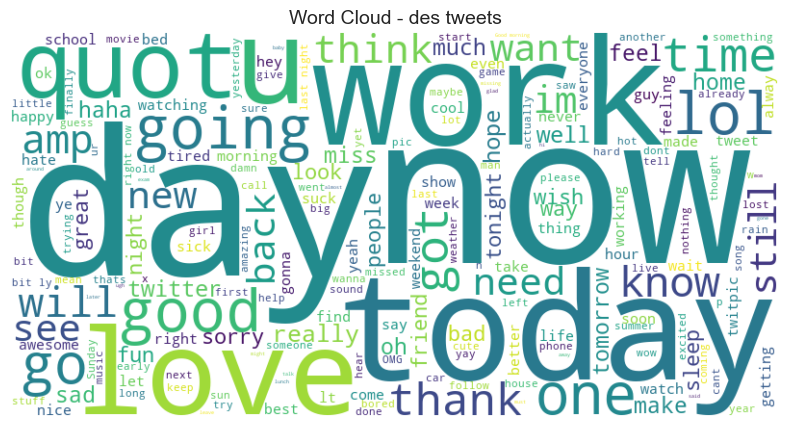

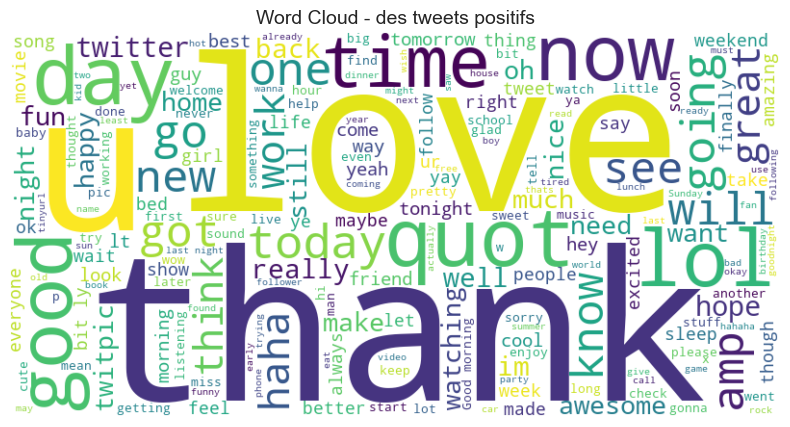

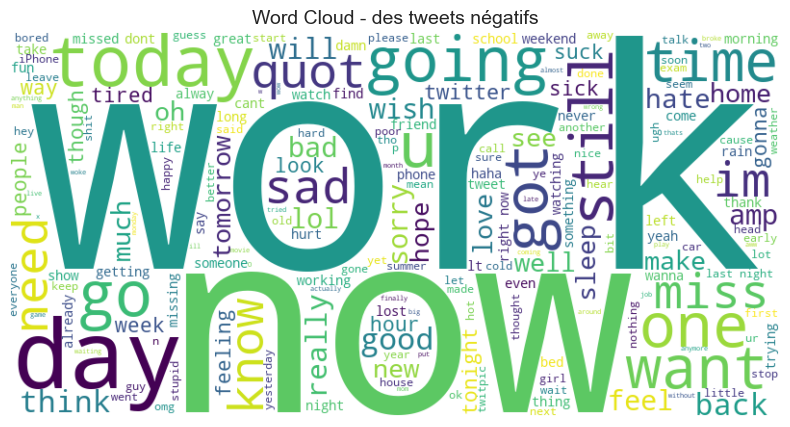

In [17]:
#Fonction pour générer le Word cloud
def generer_wordcloud(tweets, titre):
    tout_texte = ' '.join(tweets)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(tout_texte)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(titre, fontsize=14)
    plt.axis('off')
    plt.show()

#Générer le word cloud pour chaque type de sentiment
generer_wordcloud(df_select['text'], 'Word Cloud - des tweets')
generer_wordcloud(tweets_positifs['text'], 'Word Cloud - des tweets positifs')
generer_wordcloud(tweets_négatifs['text'], 'Word Cloud - des tweets négatifs')

# **Prétraitement des tweets**

**Tokenisation** La tokenisation consiste à diviser un texte en unités linguistiques plus petites appelées "tokens". Un token peut être un mot individuel, une ponctuation ou même une partie d'un mot, selon la façon dont le texte est analysé. La tokenisation est souvent réalisée en utilisant des techniques telles que la séparation par des espaces, la reconnaissance de motifs (regex) ou l'utilisation de modèles de langage.



In [25]:
import pandas as pd
import re
import nltk

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [26]:
#Création de la fonction de nétoyage

def clean_tweet(text):
    #Conversion en miniscule
    text = text.lower()
    #Suppréssion des URL
    text = re.sub(r'http\S+|www\S+', '', text)
    #Suppréssion des mention @user
    text = re.sub(r'@\w+|#\w+', '', text)
    #Suppréssion ponctuation et chiffres
    text = re.sub(r'[^a-z\s]', '', text)
    #Suppréssion espaces multiples
    text = re.sub(r'\s+', ' ', text).strip()
    return text
    


In [27]:
# tokenisation + stop words + lemmatisation

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = clean_tweet(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

In [28]:
#application sur le dataset
df_select['text_clean'] = df_select['text'].apply(preprocess)

#On fait une vérification
print(df_select[['text', 'text_clean']].head())

                                                text  \
0  Is lookin 4ward to a long weekend  really dont...   
1  #myweakness  Is music and i live to meet the p...   
2           figured out the Internet on my new iPod    
3  @hillsongunited can't wait to worship with you...   
4  @sillybeggar Congrats James !! I'm sure the bo...   

                                          text_clean  
0  lookin ward long weekend really dont want go w...  
1                        music live meet people make  
2                          figured internet new ipod  
3        cant wait worship guy tonight itll much fun  
4     congrats james im sure book going huge success  


In [30]:
df_select.sample(10)

,targets,text,text_clean
9322,1,"I wasn't expecting it to grow, but it did! So ...",wasnt expecting grow window soaking sun right
10268,0,@Mollzy sorry I didn't see it Message Jillian...,sorry didnt see message jillian ill explain
1659,1,@natblingluvsfly 5 new tracks released today (...,new track released today marked new ill let kn...
9644,1,If only we could do this Eurovision style. &qu...,could eurovision style quotthis michael east e...
1588,1,i find a healthy dose of tweetpeeps &amp; blip...,find healthy dose tweetpeeps amp blippers cure...
13131,0,Ow it hurts,ow hurt
5712,1,@intelligensia Apparently I refuses to go down...,apparently refuse go without fight muleheadedn...
14062,0,doesn't want to be awake,doesnt want awake
15522,0,@ChrissiMiller I'd love to cept I don't own an...,id love cept dont xbox play friend house local...
12278,0,let the summer work begin school and bakeside ...,let summer work begin school bakeside life


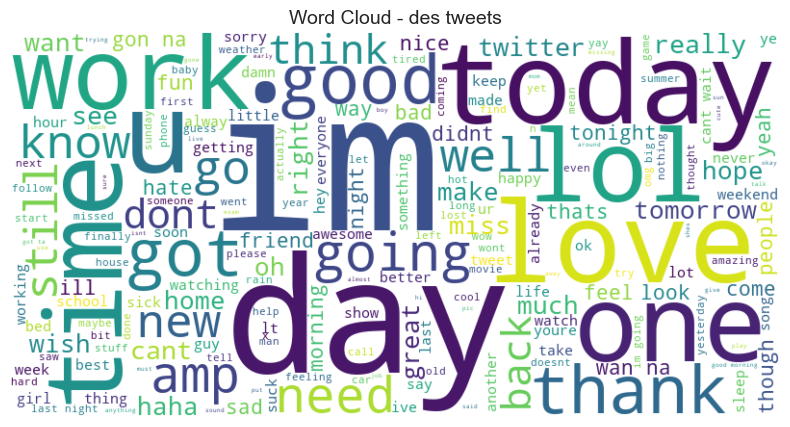

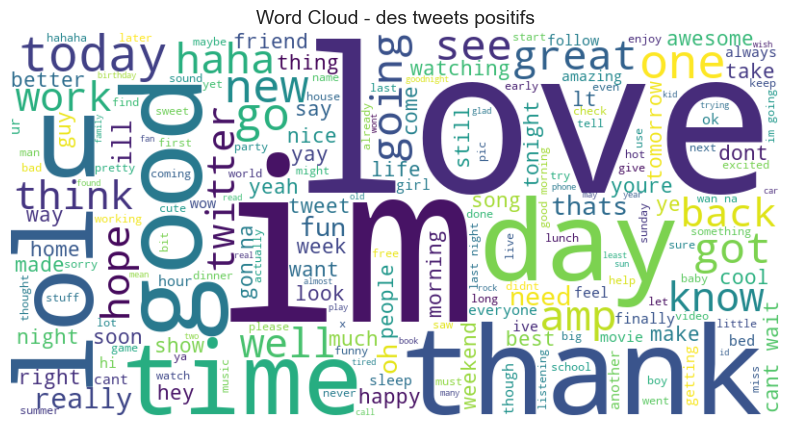

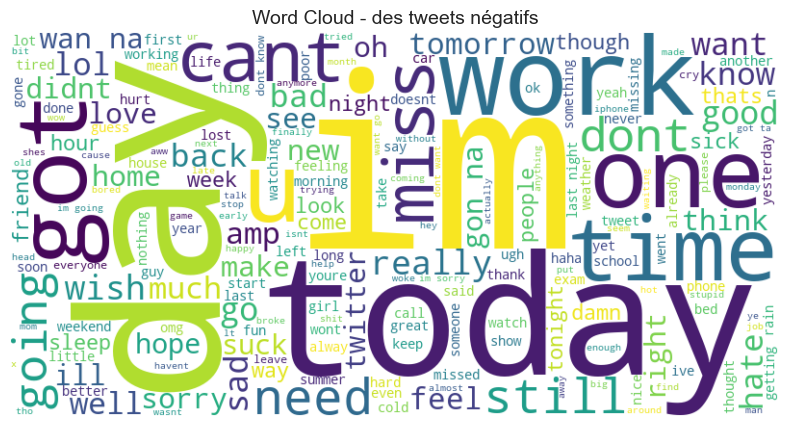

In [31]:
#Générer le word cloud pour chaque type de sentiment
generer_wordcloud(df_select['text_clean'], 'Word Cloud - des tweets')

#Filter les tweets positifs
tweets_positifs = df_select[df_select['targets'] == 1]['text_clean']
generer_wordcloud(tweets_positifs, 'Word Cloud - des tweets positifs')

#Filtrer les tweets négatifs
tweets_négatifs = df_select[df_select['targets'] == 0]['text_clean']
generer_wordcloud(tweets_négatifs, 'Word Cloud - des tweets négatifs')


# **Convertir le texte en numérique**

**TF-IDF** (Term Frequency-Inverse Document Frequency)

**TF-IDF** est une technique utilisée en traitement automatique du langage naturel **(NLP)** pour évaluer l'importance d'un terme dans un document par rapport à une collection de documents. Elle combine la fréquence du terme **(TF)** et l'inverse de la fréquence dans les documents **(IDF)**.

**TF** mesure le nombre de fois qu'un terme apparaît dans un document, tandis que **IDF** évalue l'importance d'un terme dans la collection globale de documents en réduisant le poids des termes fréquents.

En utilisant **TF-IDF**, on peut attribuer une valeur numérique à chaque terme, reflétant à la fois sa fréquence dans le document et son importance relative dans la collection de documents.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import pandas as pd


In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Créer une instance du vectoriseur TfidfVectorizer
vectorizer = TfidfVectorizer()

# Appliquer le vectoriseur sur la colonne 'texte_nettoye'
features = vectorizer.fit_transform(df_select['text_clean'])

# Convertir les caractéristiques en une représentation de matrice creuse
features = features.toarray()

# Afficher les dimensions de la matrice de caractéristiques
print("Dimensions de la matrice de caractéristiques :", features.shape)

Dimensions de la matrice de caractéristiques : (20000, 20611)


In [44]:
features

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(20000, 20611))

# **Modélisation**

In [45]:
#SPLIT en train/test
from sklearn.model_selection import train_test_split

X = features
y = df_select['targets']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {len(X_train)} tweets")
print(f"Test  : {len(X_test)} tweets")

Train : 16000 tweets
Test  : 4000 tweets


# **Logistic Regression : entraînement + prédiction**

In [ ]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)

lr_y_train_pred = lr_model.predict_proba(X_train)[:, 1]
lr_y_test_pred  = lr_model.predict_proba(X_test)[:, 1]

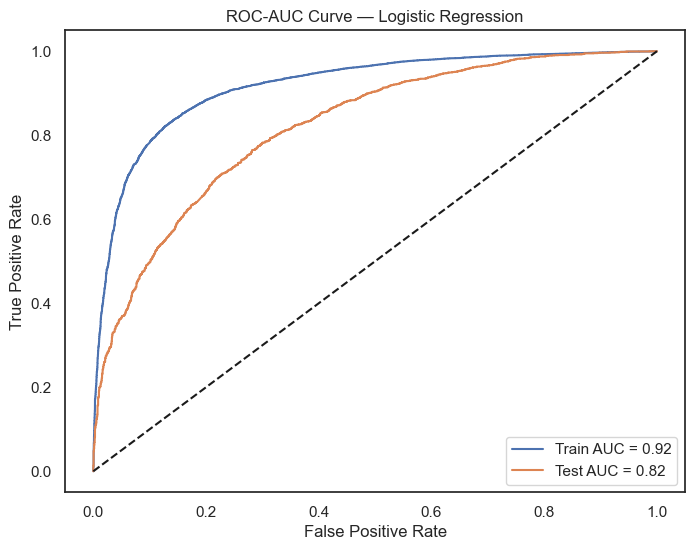

In [50]:
#Logistic Regression : ROC-AUC
fpr_train, tpr_train, _ = roc_curve(y_train, lr_y_train_pred)
fpr_test,  tpr_test,  _ = roc_curve(y_test,  lr_y_test_pred)

lr_auc_train = auc(fpr_train, tpr_train)
lr_auc_test  = auc(fpr_test,  tpr_test)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {lr_auc_train:.2f}')
plt.plot(fpr_test,  tpr_test,  label=f'Test AUC = {lr_auc_test:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve — Logistic Regression')
plt.legend(loc='lower right')
plt.show()

In [52]:
#Logistic Regression : tableau de performances
lr_perf = pd.DataFrame({
    'Performance': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Train': [
        accuracy_score(y_train,  lr_model.predict(X_train)),
        precision_score(y_train, lr_model.predict(X_train)),
        recall_score(y_train,    lr_model.predict(X_train)),
        f1_score(y_train,        lr_model.predict(X_train))
    ],
    'Test': [
        accuracy_score(y_test,   lr_model.predict(X_test)),
        precision_score(y_test,  lr_model.predict(X_test)),
        recall_score(y_test,     lr_model.predict(X_test)),
        f1_score(y_test,         lr_model.predict(X_test))
    ]
})

print("=== Logistic Regression ===")
print(lr_perf.to_string(index=False))

=== Logistic Regression ===
Performance    Train     Test
   Accuracy 0.845875 0.740500
  Precision 0.838761 0.730364
     Recall 0.856375 0.762500
   F1 Score 0.847476 0.746086


#  **Naive Bayes : entraînement + prédiction**



In [53]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

nb_y_train_pred = nb_model.predict_proba(X_train)[:, 1]
nb_y_test_pred = nb_model.predict_proba(X_test)[:, 1]

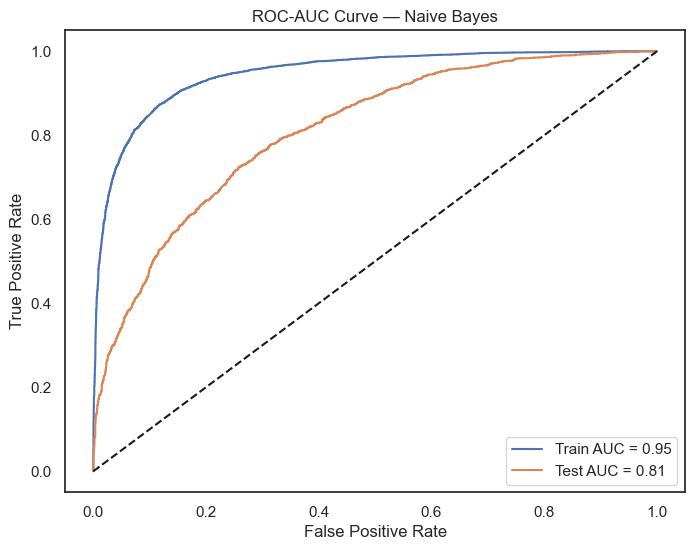

In [54]:
# Naive Bayes : ROC-AUC
fpr_train_nb, tpr_train_nb, _ = roc_curve(y_train, nb_y_train_pred)
fpr_test_nb,  tpr_test_nb,  _ = roc_curve(y_test,  nb_y_test_pred)

nb_auc_train = auc(fpr_train_nb, tpr_train_nb)
nb_auc_test  = auc(fpr_test_nb,  tpr_test_nb)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train_nb, tpr_train_nb, label=f'Train AUC = {nb_auc_train:.2f}')
plt.plot(fpr_test_nb,  tpr_test_nb,  label=f'Test AUC = {nb_auc_test:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve — Naive Bayes')
plt.legend(loc='lower right')
plt.show()

In [55]:
#Naive Bayes : tableau de performances
nb_perf = pd.DataFrame({
    'Performance': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Train': [
        accuracy_score(y_train,  nb_model.predict(X_train)),
        precision_score(y_train, nb_model.predict(X_train)),
        recall_score(y_train,    nb_model.predict(X_train)),
        f1_score(y_train,        nb_model.predict(X_train))
    ],
    'Test': [
        accuracy_score(y_test,   nb_model.predict(X_test)),
        precision_score(y_test,  nb_model.predict(X_test)),
        recall_score(y_test,     nb_model.predict(X_test)),
        f1_score(y_test,         nb_model.predict(X_test))
    ]
})

print("=== Naive Bayes ===")
print(nb_perf.to_string(index=False))

=== Naive Bayes ===
Performance    Train     Test
   Accuracy 0.874375 0.724250
  Precision 0.896374 0.748476
     Recall 0.846625 0.675500
   F1 Score 0.870789 0.710118


In [56]:
#Comparaison finale
print("=" * 40)
print("     LR vs NAIVE BAYES — COMPARAISON")
print("=" * 40)
print("\n--- Logistic Regression ---")
print(lr_perf.to_string(index=False))
print(f"AUC Test : {lr_auc_test:.2f}")
print("\n--- Naive Bayes ---")
print(nb_perf.to_string(index=False))
print(f"AUC Test : {nb_auc_test:.2f}")

     LR vs NAIVE BAYES — COMPARAISON

--- Logistic Regression ---
Performance    Train     Test
   Accuracy 0.845875 0.740500
  Precision 0.838761 0.730364
     Recall 0.856375 0.762500
   F1 Score 0.847476 0.746086
AUC Test : 0.82

--- Naive Bayes ---
Performance    Train     Test
   Accuracy 0.874375 0.724250
  Precision 0.896374 0.748476
     Recall 0.846625 0.675500
   F1 Score 0.870789 0.710118
AUC Test : 0.81


# **Sauvegarde des modèles et features**


In [57]:
import os
import joblib

os.makedirs('models', exist_ok=True)

joblib.dump(lr_model,    'models/lr_model.pkl')
joblib.dump(nb_model,    'models/nb_model.pkl')
joblib.dump(vectorizer,  'models/features.pkl')

print("Modèles sauvegardés :")
print(" - models/lr_model.pkl")
print(" - models/nb_model.pkl")
print(" - models/features.pkl")

Modèles sauvegardés :
 - models/lr_model.pkl
 - models/nb_model.pkl
 - models/features.pkl


# **Vérification**

In [58]:
lr_loaded  = joblib.load('models/lr_model.pkl')
nb_loaded  = joblib.load('models/nb_model.pkl')
vec_loaded = joblib.load('models/features.pkl')

test_tweet = ["I love this so much, amazing day !"]
test_vec   = vec_loaded.transform(test_tweet)

print("LR  →", "Positif" if lr_loaded.predict(test_vec)[0] == 1 else "Négatif")
print("NB  →", "Positif" if nb_loaded.predict(test_vec)[0] == 1 else "Négatif")

LR  → Positif
NB  → Positif
